# 0.0 Team first look (24 Sep)

The team's first exploration of the cleaned data, kept as-is for history. It is superseded by [1.0-eda.ipynb](1.0-eda.ipynb), which reorganizes and documents these ideas (feature shortlist, private/retailer flag, correlation heatmap).

Note: it loads `iphones_clean.csv` with a relative path from `data/processed/`, where it was first saved, so it won't rerun from `notebooks/` unchanged. Use `from priced_right.evaluate import load_clean` instead.

In [1]:
import pandas as pd

In [3]:
df = pd.read_csv("iphones_clean.csv")
df.columns

Index(['listing_id', 'price_eur', 'title', 'description', 'exact_model',
       'model_group', 'model_group_filled', 'release_year', 'storage_gb',
       'condition', 'battery_pct', 'mentions_warranty', 'mentions_receipt',
       'mentions_box', 'mentions_damage', 'seller_type', 'shipping_available',
       'municipality', 'region', 'listing_age_days', 'relisting_group',
       'published_at', 'collected_at'],
      dtype='str')

In [4]:
df.exact_model.unique()

<StringArray>
[    'iPhone 16 Pro',         'iPhone 12',         'iPhone 11',
         'iPhone 13', 'iPhone 14 Pro Max',         'iPhone 14',
 'iPhone 17 Pro Max',     'iPhone 17 Pro',     'iPhone 14 Pro',
         'iPhone SE',    'iPhone 13 Mini', 'iPhone 15 Pro Max',
         'iPhone 16',         'iPhone XS',         'iPhone 17',
         'iPhone 15', 'iPhone 16 Pro Max',    'iPhone 12 Mini',
     'iPhone 13 Pro', 'iPhone 12 Pro Max',     'iPhone 8 Plus',
     'iPhone 12 Pro',     'iPhone 15 Pro',        'iPhone 16e',
          'iPhone 7', 'iPhone 13 Pro Max', 'iPhone 11 Pro Max',
     'iPhone XS Max',         'iPhone XR',     'iPhone 11 Pro',
        'iPhone Air',    'iPhone 14 Plus',          'iPhone 8',
         'iPhone 6s',          'iPhone X',          'iPhone 5',
    'iPhone 15 Plus',         'iPhone 4s',    'iPhone 16 Plus',
         'iPhone 5c',        'iPhone 17e',          'iPhone 6',
         'iPhone 5s',     'iPhone 6 Plus',     'iPhone 7 Plus',
    'iPhone 6s Plus',     

In [5]:
# exact_model, storage_gb, price_eur, condition, mentions_warranty, mentions_box, mentions_damage, 

# seller_type, mentions_damage, region?

In [6]:
import seaborn as sns

In [10]:
df.describe(include = "all")

,listing_id,price_eur,title,description,exact_model,model_group,model_group_filled,release_year,storage_gb,condition,...,mentions_box,mentions_damage,seller_type,shipping_available,municipality,region,listing_age_days,relisting_group,published_at,collected_at
count,2.015000e+03,2015.000000,2015,2015,2015,2015,2015,2015.000000,1936.000000,1947,...,2015,2015,2015,2015,2015,2015,2015.000000,2015.000000,2015,2015
unique,NaN,NaN,1668,1980,48,8,2,NaN,NaN,5,...,2,2,2,2,159,18,NaN,NaN,1903,1
top,NaN,NaN,Iphone 11,Kuntoluokitus: Erinomainen Tuote on lähes uude...,iPhone 13,iPhone 2G-11,False,NaN,NaN,Hyvä,...,False,False,private,False,Helsinki,Uusimaa,NaN,NaN,2026-09-14T11:35:06+00:00,2026-09-17T11:01:58+00:00
freq,NaN,NaN,8,4,205,524,1608,NaN,NaN,954,...,1750,1716,1581,1262,467,938,NaN,NaN,10,2015
mean,4.445772e+07,330.133499,NaN,NaN,NaN,NaN,NaN,2020.773697,157.066116,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,28.609926,983.252605,NaN,NaN
std,5.913275e+06,273.518909,NaN,NaN,NaN,NaN,NaN,2.675499,133.789189,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,53.473366,575.338503,NaN,NaN
min,3.809360e+05,6.000000,NaN,NaN,NaN,NaN,NaN,2008.000000,8.000000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN
25%,4.489682e+07,130.000000,NaN,NaN,NaN,NaN,NaN,2019.000000,64.000000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,481.500000,NaN,NaN
50%,4.638756e+07,250.000000,NaN,NaN,NaN,NaN,NaN,2021.000000,128.000000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,14.000000,983.000000,NaN,NaN
75%,4.704748e+07,450.000000,NaN,NaN,NaN,NaN,NaN,2023.000000,256.000000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,39.000000,1484.500000,NaN,NaN


In [26]:
df2 = df.copy()
df2.seller_type = df2.seller_type == 'private'
df2.seller_type

0        True
1        True
2        True
3        True
4        True
        ...  
2010    False
2011    False
2012    False
2013    False
2014    False
Name: seller_type, Length: 2015, dtype: bool

<Axes: >

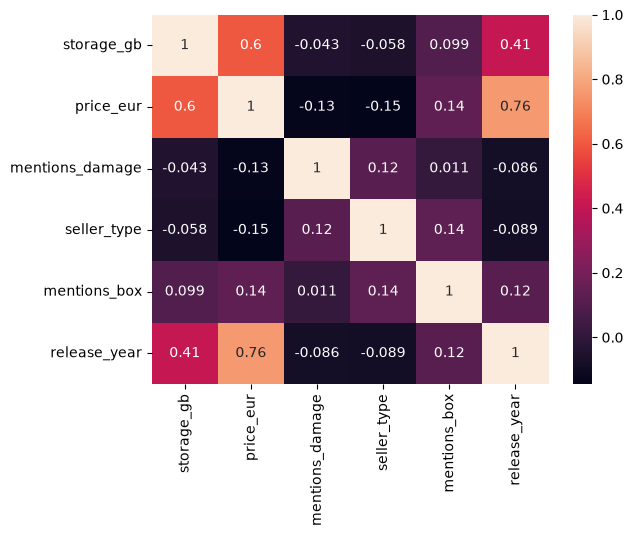

In [30]:
sns.heatmap(df2[['storage_gb', 'price_eur', 'mentions_damage', 'seller_type', 'mentions_box', 'release_year']].corr(), annot = True)

In [25]:
df.seller_type.value_counts()

seller_type
private     1581
retailer     434
Name: count, dtype: int64

In [29]:
df2[['storage_gb', 'mentions_damage', 'seller_type', 'exact_model', 'region', 'mentions_box', 'price_eur']]

,storage_gb,mentions_damage,seller_type,exact_model,region,mentions_box,price_eur
0,128.0,False,True,iPhone 16 Pro,Uusimaa,False,700
1,128.0,False,True,iPhone 12,Uusimaa,False,40
2,128.0,True,True,iPhone 11,Pirkanmaa,False,95
3,128.0,False,True,iPhone 13,Uusimaa,False,199
4,128.0,False,True,iPhone 14 Pro Max,Varsinais-Suomi,False,350
...,...,...,...,...,...,...,...
2010,128.0,False,False,iPhone 14,Pohjois-Pohjanmaa,False,449
2011,128.0,False,False,iPhone 13 Pro,Pohjois-Pohjanmaa,False,459
2012,128.0,False,False,iPhone 13,Pohjois-Pohjanmaa,False,249
2013,128.0,False,False,iPhone 14 Pro,Pohjois-Pohjanmaa,False,599
